# YOLOv11m-seg — IAN Canal & M3M Segmentation
## Full Training Run — Dental X-Ray

> **AMD RX 6800 / Windows 11 version** — Ultralytics YOLO does **not** support DirectML.
> Training runs on **CPU** locally (slow — consider Colab/CUDA for full 150 epochs).  
> All data loading, preprocessing, splits, and evaluation logic are identical to the U-Net+ResNet-50 notebook for fair comparison.
>
> **Key differences vs U-Net notebook:**
> - Single multi-class model (IAN=class 0, M3M=class 1) instead of two binary models
> - YOLO native training loop (`.train()`) replaces custom PyTorch loop
> - Data must be converted from COCO JSON → YOLO segmentation format (done in Section 6)
> - Surgical CLAHE+USM applied offline (images saved to disk) rather than on-the-fly

## 1. Setup & Installation

Install Ultralytics for YOLO11 segmentation. No `segmentation-models-pytorch` needed.

In [ ]:
# Run ONCE in your terminal/Anaconda prompt before launching Jupyter:
#
!pip install ultralytics
# Ultralytics bundles PyTorch CPU — if you already have torch installed, skip:
# !pip install torch==2.2.0 torchvision==0.17.0 --index-url https://download.pytorch.org/whl/cpu
!pip install scipy pandas matplotlib opencv-python tqdm

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 29.7 MB/s eta 0:00:00


## 2. Import Libraries

No Drive mount needed — data lives on your local disk.

In [ ]:
# Mount Drive
try:
    from google.colab import drive
    drive.mount('/content/drive')
    print("✅ Drive mounted")
except:
    print("Not in Colab or already mounted")

Mounted at /content/drive
✅ Drive mounted


In [ ]:
import os, json, random, shutil, yaml
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import cv2
from pathlib import Path
from tqdm.auto import tqdm

import torch
from scipy.spatial.distance import cdist
from ultralytics import YOLO

# ── Device: YOLO does NOT support DirectML.
#    Use CUDA if available (e.g. on Colab), otherwise fall back to CPU.
if torch.cuda.is_available():
    DEVICE = 0           # CUDA GPU index — YOLO uses integer for GPU
    DEVICE_LABEL = f'CUDA ({torch.cuda.get_device_name(0)})'
else:
    DEVICE = 'cpu'       # CPU fallback for AMD local run
    DEVICE_LABEL = 'CPU (AMD RX 6800 — no DirectML for YOLO)'

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)

set_seed(42)
print(f'✓ Running on: {DEVICE_LABEL}')
print(f'  YOLO device arg will be: {DEVICE!r}')

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
✓ Running on: CUDA (Tesla T4)
  YOLO device arg will be: 0


## 3. Configuration

⚠️ **Update the three path constants below to match your local dataset location.**  
Hyperparameters (epochs, LR, splits) are identical to the U-Net notebook.

In [ ]:
# ─── UPDATE THESE ────────────────────────────────────────────────────────────
COCO_JSON_PATH = '/content/drive/MyDrive/FINAL_YEAR/DPT_1234new/Seg_Anno/batch1-20.json'
IMAGE_DIR      = '/content/drive/MyDrive/FINAL_YEAR/DPT_1234new'
MODEL_SAVE_DIR = '/content/drive/MyDrive/FINAL_YEAR/DPT_1234new/MODELS/YOLO11m_seg'
# ─────────────────────────────────────────────────────────────────────────────

# YOLO expects a directory tree: images/train, images/val, labels/train, labels/val
WORK_DIR     = '/content/drive/MyDrive/FINAL_YEAR/DPT_1234new/MODELS/YOLO11m_seg/yolo11m_data'  # Where YOLO dataset will be written

IMG_SIZE     = 1024          # Same as U-Net
BATCH_SIZE   = 2             # Same as U-Net; increase if GPU VRAM allows
EPOCHS       = 150           # Same as U-Net
LR           = 1e-4          # Same as U-Net
SPLIT_SEED   = 42            # Same as U-Net
TRAIN_RATIO  = 0.70          # Same as U-Net
VAL_RATIO    = 0.15          # Same as U-Net
PATIENCE     = 25            # Same early-stopping patience as U-Net

# Surgical CLAHE+Unsharp parameters — identical to U-Net notebook
CANAL_STRIP_TOP    = 0.57
CANAL_STRIP_BOTTOM = 0.90
CANAL_BLEND_PAD    = 0.04

# YOLO class mapping  (order matters — must match data.yaml)
CLASS_IAN = 0
CLASS_M3M = 1
CLASS_NAMES = ['IAN_canal', 'M3M_tooth']

os.makedirs(WORK_DIR,      exist_ok=True)
os.makedirs(MODEL_SAVE_DIR, exist_ok=True)

print(f'Input size    : {IMG_SIZE}×{IMG_SIZE}')
print(f'Batch size    : {BATCH_SIZE}')
print(f'Epochs        : {EPOCHS}')
print(f'LR            : {LR}')
print(f'Early stopping: patience={PATIENCE}')
print(f'Device        : {DEVICE_LABEL}')
print(f'YOLO data dir : {WORK_DIR}')
print(f'Save dir      : {MODEL_SAVE_DIR}')

Input size    : 1024×1024
Batch size    : 2
Epochs        : 150
LR            : 0.0001
Early stopping: patience=25
Device        : CUDA (Tesla T4)
YOLO data dir : /content/drive/MyDrive/FINAL_YEAR/DPT_1234new/MODELS/YOLO11m_seg/yolo11m_data
Save dir      : /content/drive/MyDrive/FINAL_YEAR/DPT_1234new/MODELS/YOLO11m_seg


## 4. Surgical CLAHE + Unsharp Preprocessing

**Identical** to the U-Net notebook — same function, same parameters.  
The only difference is that for YOLO we apply this preprocessing **offline** (images written to disk
before training), whereas the U-Net Dataset applied it on-the-fly in `__getitem__`.

In [ ]:
def get_strip_mask(h, w, top_frac, bot_frac, pad_frac):
    """Feathered float32 blending mask for the canal strip."""
    mask   = np.zeros(h, dtype=np.float32)
    top_px = int(h * top_frac)
    bot_px = int(h * bot_frac)
    pad_px = max(1, int(h * pad_frac))
    for i in range(pad_px):
        r = top_px - pad_px + i
        if 0 <= r < h: mask[r] = i / pad_px
    mask[top_px:bot_px] = 1.0
    for i in range(pad_px):
        r = bot_px + i
        if 0 <= r < h: mask[r] = 1.0 - (i / pad_px)
    return mask[:, np.newaxis].repeat(w, axis=1)


def surgical_clahe_unsharp(img_bgr,
                            clahe_clip=2.5, clahe_tile=(6, 6),
                            sigma=1.0, weight=1.2):
    """CLAHE then unsharp masking on canal strip only, feathered blend."""
    h, w    = img_bgr.shape[:2]
    lab     = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2LAB)
    L, a, b = cv2.split(lab)
    clahe   = cv2.createCLAHE(clipLimit=clahe_clip, tileGridSize=clahe_tile)
    L_c     = clahe.apply(L)
    blurred = cv2.GaussianBlur(L_c, (0, 0), sigmaX=sigma)
    L_sharp = np.clip(cv2.addWeighted(L_c, weight, blurred, -(weight - 1.0), 0), 0, 255).astype(np.uint8)
    mask    = get_strip_mask(h, w, CANAL_STRIP_TOP, CANAL_STRIP_BOTTOM, CANAL_BLEND_PAD)
    L_blend = np.clip(L.astype(np.float32) * (1 - mask) + L_sharp.astype(np.float32) * mask, 0, 255).astype(np.uint8)
    return cv2.cvtColor(cv2.merge([L_blend, a, b]), cv2.COLOR_LAB2BGR)


print('✓ Surgical CLAHE+Unsharp preprocessing defined (identical to U-Net notebook)')

✓ Surgical CLAHE+Unsharp preprocessing defined (identical to U-Net notebook)


## 5. Load COCO Annotations & Build Train/Val/Test Splits

**Identical** to the U-Net notebook — same stratified split logic, same seed, same ratios.

In [ ]:
with open(COCO_JSON_PATH, 'r') as f:
    coco_data = json.load(f)

id_to_img      = {img['id']: img for img in coco_data['images']}
cat_name_to_id = {cat['name']: cat['id'] for cat in coco_data['categories']}

ian_key    = next(k for k in cat_name_to_id if 'IDN' in k or 'canal' in k.lower())
m3m_key    = next(k for k in cat_name_to_id if 'molar' in k.lower() or 'Mandibular' in k)
IAN_CAT_ID = cat_name_to_id[ian_key]
M3M_CAT_ID = cat_name_to_id[m3m_key]
print(f'IAN category: "{ian_key}" (id={IAN_CAT_ID}) → YOLO class {CLASS_IAN}')
print(f'M3M category: "{m3m_key}" (id={M3M_CAT_ID}) → YOLO class {CLASS_M3M}')

# Build image → annotations lookup
img_to_anns = {}
for ann in coco_data['annotations']:
    img_to_anns.setdefault(ann['image_id'], []).append(ann)

# Keep only images that exist on disk AND have at least one annotation
matched = [
    img for img in coco_data['images']
    if os.path.exists(os.path.join(IMAGE_DIR, img['file_name']))
    and img['id'] in img_to_anns
]
print(f'\n✓ Matched images: {len(matched)}')

# Stratified split — ensure IAN images distributed across splits
ian_imgs   = [m for m in matched if any(a['category_id'] == IAN_CAT_ID for a in img_to_anns[m['id']])]
noian_imgs = [m for m in matched if m not in ian_imgs]

random.seed(SPLIT_SEED)
random.shuffle(ian_imgs)
random.shuffle(noian_imgs)

def split_list(lst, train_r, val_r):
    n = len(lst)
    return lst[:int(n * train_r)], lst[int(n * train_r):int(n * (train_r + val_r))], lst[int(n * (train_r + val_r)):]

ian_tr, ian_val, ian_te       = split_list(ian_imgs,   TRAIN_RATIO, VAL_RATIO)
noian_tr, noian_val, noian_te = split_list(noian_imgs, TRAIN_RATIO, VAL_RATIO)

SPLITS = {
    'train': ian_tr + noian_tr,
    'val':   ian_val + noian_val,
    'test':  ian_te + noian_te,
}

print('\nDataset split (stratified by IAN presence, seed=42) — identical to U-Net:')
for s, imgs in SPLITS.items():
    ian_c = sum(1 for m in imgs if any(a['category_id'] == IAN_CAT_ID for a in img_to_anns[m['id']]))
    print(f'  {s:5s}: {len(imgs):3d} images  ({ian_c} with IAN canal)')

IAN category: "IDN canal" (id=2) → YOLO class 0
M3M category: "Mandibular Third molar" (id=1) → YOLO class 1

✓ Matched images: 480

Dataset split (stratified by IAN presence, seed=42) — identical to U-Net:
  train: 335 images  (331 with IAN canal)
  val  :  72 images  (71 with IAN canal)
  test :  73 images  (72 with IAN canal)


## 6. Convert COCO → YOLO Segmentation Format

YOLO segmentation expects:
```
yolo_data/
  images/train/  images/val/  images/test/
  labels/train/  labels/val/  labels/test/
```
Each label `.txt` contains one line per instance:
```
<class_id>  <x1_norm> <y1_norm>  <x2_norm> <y2_norm>  ... <xn_norm> <yn_norm>
```
Coordinates are normalised to [0, 1] by `img_w` / `img_h`.

We also apply Surgical CLAHE+USM here (offline), so YOLO sees preprocessed images during training — equivalent to the U-Net on-the-fly preprocessing.

In [ ]:
def coco_to_yolo_polygon(segmentation, img_w, img_h):
    """
    Convert a single COCO polygon (flat list of [x,y,x,y,...]) to
    a YOLO-normalised flat list [x1/w, y1/h, x2/w, y2/h, ...].
    Returns None if the polygon has fewer than 3 points.
    """
    pts = np.array(segmentation, dtype=np.float32).reshape(-1, 2)
    if len(pts) < 3:
        return None
    # Clip to image bounds
    pts[:, 0] = np.clip(pts[:, 0], 0, img_w)
    pts[:, 1] = np.clip(pts[:, 1], 0, img_h)
    pts[:, 0] /= img_w
    pts[:, 1] /= img_h
    return pts.flatten().tolist()


def write_yolo_dataset(splits, image_dir, img_to_anns, ian_cat_id, m3m_cat_id,
                        out_dir, img_size):
    """
    For each split (train/val/test):
      1. Apply Surgical CLAHE+USM to each image and save at img_size×img_size.
      2. Write corresponding YOLO label .txt file with all IAN + M3M polygons.
    """
    coco_to_yolo_class = {ian_cat_id: CLASS_IAN, m3m_cat_id: CLASS_M3M}

    for split, img_infos in splits.items():
        img_out  = os.path.join(out_dir, 'images', split)
        lbl_out  = os.path.join(out_dir, 'labels', split)
        os.makedirs(img_out, exist_ok=True)
        os.makedirs(lbl_out, exist_ok=True)

        skipped = 0
        for info in tqdm(img_infos, desc=f'Writing {split}'):
            src_path = os.path.join(image_dir, info['file_name'])
            stem     = Path(info['file_name']).stem

            # ── Read & preprocess image ──────────────────────────────────────
            img_bgr = cv2.imread(src_path)
            if img_bgr is None:
                skipped += 1
                continue
            img_proc  = surgical_clahe_unsharp(img_bgr)
            img_resized = cv2.resize(img_proc, (img_size, img_size), interpolation=cv2.INTER_LINEAR)
            cv2.imwrite(os.path.join(img_out, f'{stem}.jpg'), img_resized)

            # ── Build YOLO label file ────────────────────────────────────────
            anns     = img_to_anns.get(info['id'], [])
            orig_h   = info['height']
            orig_w   = info['width']
            lines    = []
            for ann in anns:
                yolo_cls = coco_to_yolo_class.get(ann['category_id'])
                if yolo_cls is None:
                    continue  # ignore other categories
                for seg in ann.get('segmentation', []):
                    norm_pts = coco_to_yolo_polygon(seg, orig_w, orig_h)
                    if norm_pts is None:
                        continue
                    coords_str = ' '.join(f'{v:.6f}' for v in norm_pts)
                    lines.append(f'{yolo_cls} {coords_str}')

            with open(os.path.join(lbl_out, f'{stem}.txt'), 'w') as f:
                f.write('\n'.join(lines))

        print(f'  ✓ {split}: {len(img_infos) - skipped} images written  '
              f'({skipped} skipped — missing on disk)')


print('Starting COCO → YOLO conversion with Surgical CLAHE+USM preprocessing...')
print('(This writes preprocessed images to disk — runs once; skip if already done)\n')

write_yolo_dataset(
    splits      = SPLITS,
    image_dir   = IMAGE_DIR,
    img_to_anns = img_to_anns,
    ian_cat_id  = IAN_CAT_ID,
    m3m_cat_id  = M3M_CAT_ID,
    out_dir     = WORK_DIR,
    img_size    = IMG_SIZE,
)
print('\n✓ Dataset conversion complete')

Starting COCO → YOLO conversion with Surgical CLAHE+USM preprocessing...
(This writes preprocessed images to disk — runs once; skip if already done)



Writing train:   0%|          | 0/335 [00:00<?, ?it/s]

  ✓ train: 335 images written  (0 skipped — missing on disk)


Writing val:   0%|          | 0/72 [00:00<?, ?it/s]

  ✓ val: 72 images written  (0 skipped — missing on disk)


Writing test:   0%|          | 0/73 [00:00<?, ?it/s]

  ✓ test: 73 images written  (0 skipped — missing on disk)

✓ Dataset conversion complete


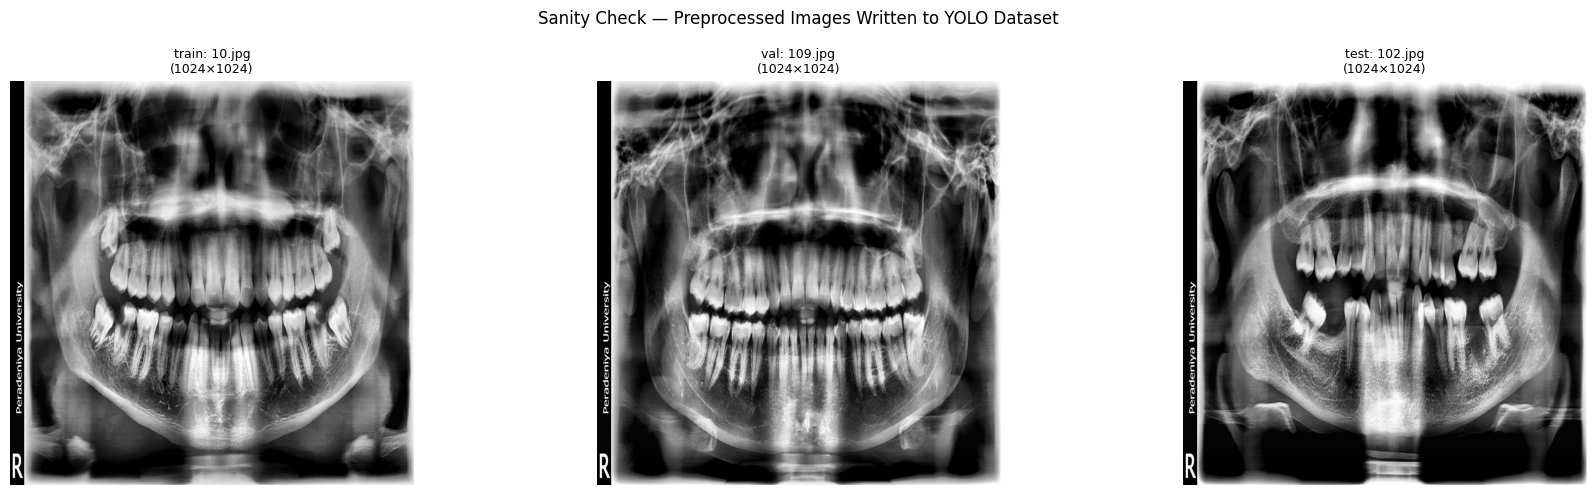

train: 335 images | 644 IAN polygon instances | 679 M3M instances
val  : 72 images | 142 IAN polygon instances | 142 M3M instances
test : 73 images | 137 IAN polygon instances | 148 M3M instances


In [ ]:
# ── Sanity check — display one preprocessed sample from each split ──────────
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle('Sanity Check — Preprocessed Images Written to YOLO Dataset', fontsize=12)

for ax, split in zip(axes, ['train', 'val', 'test']):
    img_dir = os.path.join(WORK_DIR, 'images', split)
    sample  = sorted(os.listdir(img_dir))[0]
    img_bgr = cv2.imread(os.path.join(img_dir, sample))
    ax.imshow(cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB))
    ax.set_title(f'{split}: {sample}\n({img_bgr.shape[1]}×{img_bgr.shape[0]})', fontsize=9)
    ax.axis('off')

plt.tight_layout()
plt.savefig(os.path.join(MODEL_SAVE_DIR, 'dataset_sanity.png'), dpi=120, bbox_inches='tight')
plt.show()

# Count label files and check class balance
for split in ['train', 'val', 'test']:
    lbl_dir    = os.path.join(WORK_DIR, 'labels', split)
    ian_count  = m3m_count = 0
    for txt in os.listdir(lbl_dir):
        with open(os.path.join(lbl_dir, txt)) as f:
            for line in f:
                cls = int(line.strip().split()[0]) if line.strip() else -1
                if cls == CLASS_IAN: ian_count += 1
                elif cls == CLASS_M3M: m3m_count += 1
    n_img = len(os.listdir(os.path.join(WORK_DIR, 'images', split)))
    print(f'{split:5s}: {n_img} images | {ian_count} IAN polygon instances | {m3m_count} M3M instances')

## 7. Create data.yaml

YOLO reads dataset structure from a YAML file.

In [ ]:
data_yaml_path = os.path.join(WORK_DIR, 'data.yaml')

data_cfg = {
    'path':  WORK_DIR,
    'train': os.path.join(WORK_DIR, 'images', 'train'),
    'val':   os.path.join(WORK_DIR, 'images', 'val'),
    'test':  os.path.join(WORK_DIR, 'images', 'test'),
    'nc':    2,
    'names': CLASS_NAMES,   # ['IAN_canal', 'M3M_tooth']
}

with open(data_yaml_path, 'w') as f:
    yaml.dump(data_cfg, f, default_flow_style=False, sort_keys=False)

print(f'✓ data.yaml written to: {data_yaml_path}')
print()
with open(data_yaml_path) as f:
    print(f.read())

✓ data.yaml written to: /content/drive/MyDrive/FINAL_YEAR/DPT_1234new/MODELS/YOLO11m_seg/yolo11m_data/data.yaml

path: /content/drive/MyDrive/FINAL_YEAR/DPT_1234new/MODELS/YOLO11m_seg/yolo11m_data
train: /content/drive/MyDrive/FINAL_YEAR/DPT_1234new/MODELS/YOLO11m_seg/yolo11m_data/images/train
val: /content/drive/MyDrive/FINAL_YEAR/DPT_1234new/MODELS/YOLO11m_seg/yolo11m_data/images/val
test: /content/drive/MyDrive/FINAL_YEAR/DPT_1234new/MODELS/YOLO11m_seg/yolo11m_data/images/test
nc: 2
names:
- IAN_canal
- M3M_tooth



## 8. Build YOLOv11m-seg Model

YOLOv11m-seg is the medium variant of the YOLO11 instance segmentation family.  
Loaded from the pretrained ImageNet/COCO checkpoint for transfer learning.

In [ ]:
# Load pretrained YOLOv11m-seg
# Ultralytics will auto-download yolo11m-seg.pt on first run
model = YOLO('yolo11m-seg.pt')

# Parameter count (approximate)
total_params = sum(p.numel() for p in model.model.parameters()) / 1e6
print(f'✓ YOLOv11m-seg loaded')
print(f'  Parameters  : {total_params:.1f}M')
print(f'  Running on  : {DEVICE_LABEL}')
print()
print('  Note: U-Net+ResNet50 has ~32M params per model (×2 = ~64M total).')
print('  YOLOv11m-seg handles both classes in a single model.')

✓ YOLOv11m-seg loaded
  Parameters  : 22.4M
  Running on  : CUDA (Tesla T4)

  Note: U-Net+ResNet50 has ~32M params per model (×2 = ~64M total).
  YOLOv11m-seg handles both classes in a single model.


## 9. Train YOLOv11m-seg

Hyperparameters are matched to the U-Net notebook where YOLO allows:
- `epochs=150`, `batch=2`, `lr0=1e-4`, `optimizer='AdamW'`
- `patience=25` (early stopping)
- Augmentation: comparable to U-Net transforms (HFlip, ShiftScaleRotate, brightness/contrast, noise)
- `mosaic=0.0` — disabled; mosaic distorts medical anatomy
- `mixup=0.0` — disabled for the same reason

> ⏱ **Training time:** CPU ≈ very slow (hours per epoch at IMG_SIZE=1024).  
> For local testing, reduce `imgsz=640` and `epochs=10` first.  
> Full 150-epoch run is best done on Colab with a T4/A100 GPU.

In [ ]:
results = model.train(
    data        = data_yaml_path,
    epochs      = EPOCHS,          # 150 — same as U-Net
    imgsz       = IMG_SIZE,        # 1024 — same as U-Net
    batch       = BATCH_SIZE,      # 2 — same as U-Net
    device      = DEVICE,          # 'cpu' locally; 0 on Colab
    optimizer   = 'AdamW',         # same as U-Net
    lr0         = LR,              # 1e-4 — same as U-Net
    lrf         = 0.01,            # final LR = lr0 * lrf → ~1e-6 (≈ LR_MIN in U-Net)
    weight_decay= 1e-4,            # same as U-Net AdamW weight_decay
    patience    = PATIENCE,        # 25 — same as U-Net EarlyStopping
    # ── Augmentation (comparable to U-Net albumentations pipeline) ──────────
    fliplr      = 0.5,             # HorizontalFlip p=0.5
    flipud      = 0.0,
    degrees     = 5.0,             # rotate_limit=5
    translate   = 0.05,            # shift_limit=0.05
    scale       = 0.1,             # scale_limit=0.1
    hsv_h       = 0.0,             # no hue shift for X-rays
    hsv_s       = 0.0,             # no saturation for grayscale X-rays
    hsv_v       = 0.1,             # ≈ RandomBrightnessContrast
    mosaic      = 0.0,             # DISABLED — mosaic distorts anatomy
    mixup       = 0.0,             # DISABLED
    copy_paste  = 0.0,             # DISABLED
    # ── Output paths ────────────────────────────────────────────────────────
    project     = MODEL_SAVE_DIR,
    name        = 'yolo11m_seg_run',
    save        = True,
    save_period = -1,              # only save best + last
    exist_ok    = True,
    verbose     = True,
    workers     = 0,               # DirectML/CPU — must be 0
)

print('\n✓ Training complete')
RUN_DIR   = os.path.join(MODEL_SAVE_DIR, 'yolo11m_seg_run')
BEST_PT   = os.path.join(RUN_DIR, 'weights', 'best.pt')
print(f'  Best weights : {BEST_PT}')

Ultralytics 8.4.24 🚀 Python-3.12.12 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=2, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drive/MyDrive/FINAL_YEAR/DPT_1234new/MODELS/YOLO11m_seg/yolo11m_data/data.yaml, degrees=5.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=150, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.0, hsv_s=0.0, hsv_v=0.1, imgsz=1024, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.0001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11m-seg.pt, momentum=0.937, mosaic=0.0, multi_scale=0.0, name=yolo11m_seg_run, nbs=64, nms=False, opset=None, optimiz

## 10. Training Curves

Ultralytics writes `results.csv` to the run directory after training.

In [ ]:
csv_path = os.path.join(RUN_DIR, 'results.csv')
df_res   = pd.read_csv(csv_path)
df_res.columns = df_res.columns.str.strip()  # Ultralytics sometimes adds spaces

print('Available columns:', df_res.columns.tolist())
print(df_res.head(3))

Available columns: ['epoch', 'time', 'train/box_loss', 'train/seg_loss', 'train/cls_loss', 'train/dfl_loss', 'train/sem_loss', 'metrics/precision(B)', 'metrics/recall(B)', 'metrics/mAP50(B)', 'metrics/mAP50-95(B)', 'metrics/precision(M)', 'metrics/recall(M)', 'metrics/mAP50(M)', 'metrics/mAP50-95(M)', 'val/box_loss', 'val/seg_loss', 'val/cls_loss', 'val/dfl_loss', 'val/sem_loss', 'lr/pg0', 'lr/pg1', 'lr/pg2']
   epoch      time  train/box_loss  train/seg_loss  train/cls_loss  \
0      1   78.3469         1.28960         2.01214         1.20467   
1      2  143.7910         1.05320         1.48201         0.66927   
2      3  214.7660         0.99564         1.36360         0.59103   

   train/dfl_loss  train/sem_loss  metrics/precision(B)  metrics/recall(B)  \
0         1.51522               0               0.90774            0.87545   
1         1.31459               0               0.92388            0.90493   
2         1.25891               0               0.92865            0.921

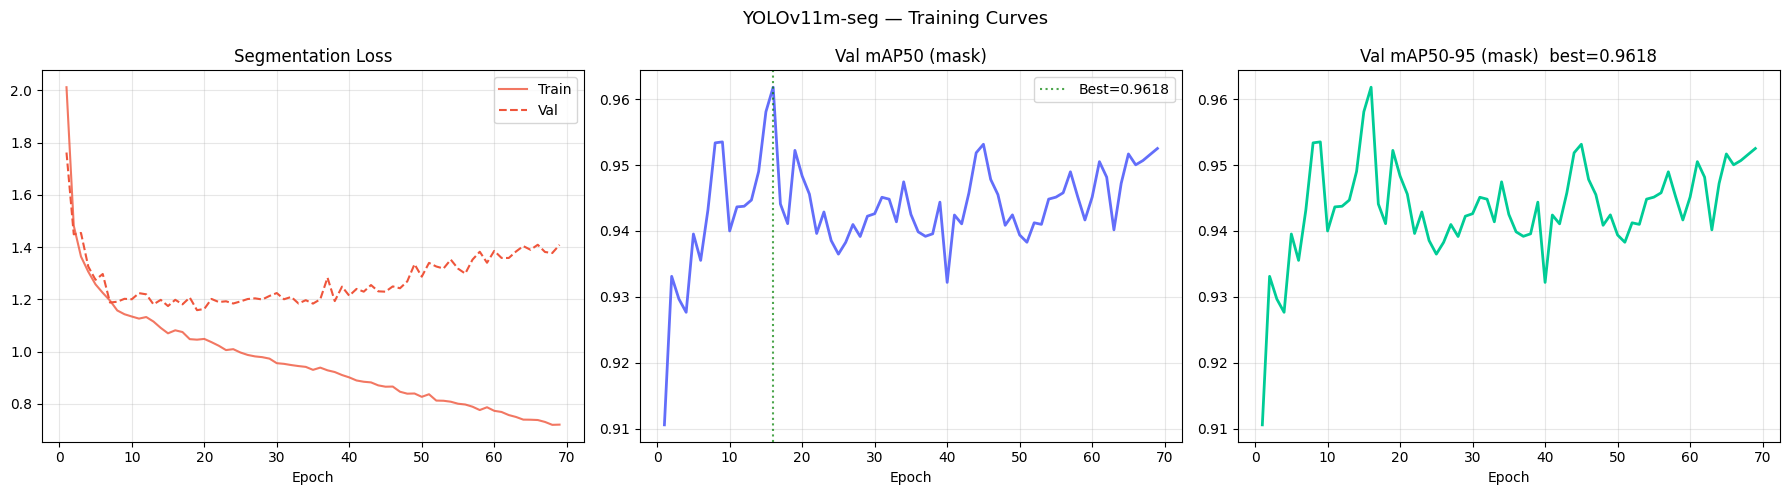

✓ Saved: /content/drive/MyDrive/FINAL_YEAR/DPT_1234new/MODELS/YOLO11m_seg/training_curves.png


In [ ]:
# Map to friendly names — column names may vary by Ultralytics version
# Common columns: train/box_loss, train/seg_loss, val/box_loss, val/seg_loss,
#                 metrics/mAP50(M), metrics/mAP50-95(M)
epoch_x = df_res['epoch'] if 'epoch' in df_res.columns else range(1, len(df_res) + 1)

# Find seg loss columns dynamically
train_seg_col = next((c for c in df_res.columns if 'train' in c and 'seg' in c), None)
val_seg_col   = next((c for c in df_res.columns if 'val'   in c and 'seg' in c), None)
map50_col     = next((c for c in df_res.columns if 'mAP50' in c and '95' not in c), None)
map5095_col   = next((c for c in df_res.columns if 'mAP50-95' in c or 'mAP50(B)' in c), None)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle('YOLOv11m-seg — Training Curves', fontsize=13)

# Seg loss
if train_seg_col and val_seg_col:
    axes[0].plot(epoch_x, df_res[train_seg_col], color='#EF553B', lw=1.5, alpha=0.8, label='Train')
    axes[0].plot(epoch_x, df_res[val_seg_col],   color='#EF553B', lw=1.5, ls='--', label='Val')
axes[0].set_title('Segmentation Loss'); axes[0].set_xlabel('Epoch')
axes[0].legend(); axes[0].grid(alpha=0.3)

# mAP50
if map50_col:
    axes[1].plot(epoch_x, df_res[map50_col], color='#636EFA', lw=2)
    best_ep  = df_res[map50_col].idxmax()
    best_val = df_res[map50_col].max()
    axes[1].axvline(epoch_x.iloc[best_ep] if hasattr(epoch_x, 'iloc') else best_ep,
                    color='green', ls=':', alpha=0.7, label=f'Best={best_val:.4f}')
axes[1].set_title('Val mAP50 (mask)'); axes[1].set_xlabel('Epoch')
axes[1].legend(); axes[1].grid(alpha=0.3)

# mAP50-95
if map5095_col:
    axes[2].plot(epoch_x, df_res[map5095_col], color='#00CC96', lw=2)
    best_val2 = df_res[map5095_col].max()
    axes[2].set_title(f'Val mAP50-95 (mask)  best={best_val2:.4f}')
axes[2].set_xlabel('Epoch'); axes[2].grid(alpha=0.3)

plt.tight_layout()
curve_path = os.path.join(MODEL_SAVE_DIR, 'training_curves.png')
plt.savefig(curve_path, dpi=150, bbox_inches='tight')
plt.show()
print(f'✓ Saved: {curve_path}')

## 11. Test Set Evaluation

Evaluates the best checkpoint on the held-out test split using the **same metrics** as the U-Net notebook:
- **Dice coefficient**
- **IoU** (Jaccard index)
- **Precision / Recall**
- **mAP50-95 approximation** — threshold sweep at IoU 0.50, 0.55, …, 0.95

The `compute_map_approx` function is identical to the U-Net notebook, ensuring directly comparable numbers.

In [ ]:
# ── Helper: render COCO polygon → binary mask (identical to U-Net notebook) ──
def coco_polygons_to_mask(annotations, cat_id, img_h, img_w, target_size):
    """
    Render all polygons of category `cat_id` from `annotations` into a
    binary mask of shape (target_size, target_size).
    Uses NEAREST interpolation to avoid blurring mask edges.
    Returns float32 mask in [0, 1].
    """
    mask = np.zeros((img_h, img_w), dtype=np.uint8)
    for ann in annotations:
        if ann['category_id'] != cat_id:
            continue
        for seg in ann.get('segmentation', []):
            if len(seg) < 6:
                continue
            pts = np.array(seg, dtype=np.float32).reshape(-1, 2).astype(np.int32)
            cv2.fillPoly(mask, [pts], 1)
    if target_size != img_h or target_size != img_w:
        mask = cv2.resize(mask, (target_size, target_size),
                          interpolation=cv2.INTER_NEAREST)
    return mask.astype(np.float32)


# ── Helper: YOLO prediction → per-class binary mask ─────────────────────────
def yolo_masks_to_binary(result, class_id, img_size):
    """
    Given a single Ultralytics Results object, extract and merge all instance
    masks belonging to `class_id` into a single binary numpy mask of shape
    (img_size, img_size).
    Returns float32 array in {0, 1}.
    """
    merged = np.zeros((img_size, img_size), dtype=np.float32)
    if result.masks is None:
        return merged
    classes = result.boxes.cls.cpu().numpy().astype(int)
    masks   = result.masks.data.cpu().numpy()  # (N, H, W) — may be at reduced res
    for cls, msk in zip(classes, masks):
        if cls != class_id:
            continue
        # Resize mask to IMG_SIZE if YOLO output is at lower resolution
        if msk.shape[0] != img_size or msk.shape[1] != img_size:
            msk = cv2.resize(msk, (img_size, img_size), interpolation=cv2.INTER_NEAREST)
        merged = np.clip(merged + (msk > 0.5).astype(np.float32), 0, 1)
    return merged


print('✓ Evaluation helpers defined')

✓ Evaluation helpers defined


In [ ]:
# ── Metric functions — identical to U-Net notebook ───────────────────────────
def dice_score_np(pred_bin, gt_bin, smooth=1.0):
    """NumPy Dice coefficient for flat binary arrays."""
    inter = (pred_bin * gt_bin).sum()
    denom = pred_bin.sum() + gt_bin.sum() + smooth
    return float((2.0 * inter + smooth) / denom)


def iou_score_np(pred_bin, gt_bin, smooth=1.0):
    inter = (pred_bin * gt_bin).sum()
    union = pred_bin.sum() + gt_bin.sum() - inter + smooth
    return float((inter + smooth) / union)


def precision_recall_np(pred_bin, gt_bin):
    tp = (pred_bin * gt_bin).sum()
    fp = (pred_bin * (1 - gt_bin)).sum()
    fn = ((1 - pred_bin) * gt_bin).sum()
    prec = float(tp / (tp + fp + 1e-8))
    rec  = float(tp / (tp + fn + 1e-8))
    return prec, rec


def compute_map_approx_yolo(best_model, test_img_infos, img_to_anns,
                              ian_cat_id, m3m_cat_id, img_dir, img_size,
                              iou_thresholds=None):
    if iou_thresholds is None:
        iou_thresholds = np.arange(0.50, 1.00, 0.05)

    ian_aps, m3m_aps = [], []

    for t in tqdm(iou_thresholds, desc='mAP threshold sweep'):
        ian_tp = ian_fp = ian_fn = 0
        m3m_tp = m3m_fp = m3m_fn = 0

        for info in test_img_infos:
            stem     = Path(info['file_name']).stem
            img_path = os.path.join(img_dir, 'images', 'test', f'{stem}.jpg')
            if not os.path.exists(img_path):
                continue

            anns   = img_to_anns.get(info['id'], [])
            h, w   = info['height'], info['width']
            ian_gt = coco_polygons_to_mask(anns, ian_cat_id, h, w, img_size)
            m3m_gt = coco_polygons_to_mask(anns, m3m_cat_id, h, w, img_size)

            res      = best_model.predict(img_path, imgsz=img_size, conf=0.25, verbose=False)[0]
            ian_pred = yolo_masks_to_binary(res, CLASS_IAN, img_size)
            m3m_pred = yolo_masks_to_binary(res, CLASS_M3M, img_size)

            for pred, gt in [(ian_pred, ian_gt), (m3m_pred, m3m_gt)]:
                inter    = (pred * gt).sum()
                union    = (pred + gt - pred * gt).sum()
                img_iou  = float((inter + 1e-8) / (union + 1e-8))
                has_gt   = gt.sum() > 0
                has_pred = pred.sum() > 0

                if pred is ian_pred:
                    if img_iou >= t:                  ian_tp += 1
                    elif has_pred and not has_gt:     ian_fp += 1
                    elif not has_pred and has_gt:     ian_fn += 1
                else:
                    if img_iou >= t:                  m3m_tp += 1
                    elif has_pred and not has_gt:     m3m_fp += 1
                    elif not has_pred and has_gt:     m3m_fn += 1

        ian_aps.append((ian_tp + 1e-8) / (ian_tp + ian_fp + ian_fn + 1e-8))
        m3m_aps.append((m3m_tp + 1e-8) / (m3m_tp + m3m_fp + m3m_fn + 1e-8))

    return {
        'IAN': {'mAP50-95': float(np.mean(ian_aps)), 'mAP50': float(ian_aps[0])},
        'M3M': {'mAP50-95': float(np.mean(m3m_aps)), 'mAP50': float(m3m_aps[0])},
    }


print('✓ mAP50-95 sweep function defined (same method as U-Net notebook)')

✓ mAP50-95 sweep function defined (same method as U-Net notebook)


In [ ]:
# ── Load best weights ─────────────────────────────────────────────────────────
best_model = YOLO(BEST_PT)
print(f'✓ Loaded best weights from: {BEST_PT}')

# ── Per-image Dice / IoU / Precision / Recall ─────────────────────────────────
ian_dice_list = []; ian_iou_list  = []
m3m_dice_list = []; m3m_iou_list  = []
ian_prec_list = []; ian_rec_list  = []
m3m_prec_list = []; m3m_rec_list  = []

for info in tqdm(SPLITS['test'], desc='Test set evaluation'):
    stem     = Path(info['file_name']).stem
    img_path = os.path.join(WORK_DIR, 'images', 'test', f'{stem}.jpg')
    if not os.path.exists(img_path):
        continue

    anns   = img_to_anns.get(info['id'], [])
    h, w   = info['height'], info['width']
    ian_gt = coco_polygons_to_mask(anns, IAN_CAT_ID, h, w, IMG_SIZE)
    m3m_gt = coco_polygons_to_mask(anns, M3M_CAT_ID, h, w, IMG_SIZE)

    res      = best_model.predict(img_path, imgsz=IMG_SIZE, conf=0.25, verbose=False)[0]
    ian_pred = yolo_masks_to_binary(res, CLASS_IAN, IMG_SIZE)
    m3m_pred = yolo_masks_to_binary(res, CLASS_M3M, IMG_SIZE)

    ian_dice_list.append(dice_score_np(ian_pred, ian_gt))
    ian_iou_list.append(iou_score_np(ian_pred, ian_gt))
    m3m_dice_list.append(dice_score_np(m3m_pred, m3m_gt))
    m3m_iou_list.append(iou_score_np(m3m_pred, m3m_gt))
    p, r = precision_recall_np(ian_pred, ian_gt); ian_prec_list.append(p); ian_rec_list.append(r)
    p, r = precision_recall_np(m3m_pred, m3m_gt); m3m_prec_list.append(p); m3m_rec_list.append(r)

print('\nRunning mAP50-95 threshold sweep (matches U-Net evaluation method)...')
map_metrics = compute_map_approx_yolo(
    best_model, SPLITS['test'], img_to_anns,
    IAN_CAT_ID, M3M_CAT_ID, WORK_DIR, IMG_SIZE
)

ian_test_metrics = {
    'Dice':      float(np.mean(ian_dice_list)),
    'IoU':       float(np.mean(ian_iou_list)),
    'Precision': float(np.mean(ian_prec_list)),
    'Recall':    float(np.mean(ian_rec_list)),
    'mAP50':     map_metrics['IAN']['mAP50'],
    'mAP50-95':  map_metrics['IAN']['mAP50-95'],
}
m3m_test_metrics = {
    'Dice':      float(np.mean(m3m_dice_list)),
    'IoU':       float(np.mean(m3m_iou_list)),
    'Precision': float(np.mean(m3m_prec_list)),
    'Recall':    float(np.mean(m3m_rec_list)),
    'mAP50':     map_metrics['M3M']['mAP50'],
    'mAP50-95':  map_metrics['M3M']['mAP50-95'],
}

print('\n' + '=' * 60)
print('TEST SET METRICS — YOLOv11m-seg')
print('=' * 60)
for label, metrics, target_flag in [
    ('IAN Canal', ian_test_metrics, True),
    ('M3M Tooth', m3m_test_metrics, False),
]:
    print(f'\n  {label}:')
    for k, v in metrics.items():
        flag = '  ← PRIMARY TARGET' if k == 'mAP50-95' and target_flag else ''
        print(f'    {k:<14}: {v:.4f}{flag}')
print('=' * 60)

✓ Loaded best weights from: /content/drive/MyDrive/FINAL_YEAR/DPT_1234new/MODELS/YOLO11m_seg/yolo11m_seg_run/weights/best.pt


Test set evaluation:   0%|          | 0/73 [00:00<?, ?it/s]


Running mAP50-95 threshold sweep (matches U-Net evaluation method)...


mAP threshold sweep:   0%|          | 0/10 [00:00<?, ?it/s]


TEST SET METRICS — YOLOv11m-seg

  IAN Canal:
    Dice          : 0.6490
    IoU           : 0.4987
    Precision     : 0.6327
    Recall        : 0.6901
    mAP50         : 0.9545
    mAP50-95      : 0.3888  ← PRIMARY TARGET

  M3M Tooth:
    Dice          : 0.8699
    IoU           : 0.7799
    Precision     : 0.8560
    Recall        : 0.8993
    mAP50         : 1.0000
    mAP50-95      : 1.0000


## 12. Comparison Table — All Models

Extends the comparison from the U-Net notebook with YOLOv11m-seg results.

                   Model  IAN mAP50  IAN mAP50-95  M3M mAP50-95  All mAP50-95
        YOLOv8s baseline     0.3549        0.0651        0.5918        0.3285
YOLO11s + Surgical CLAHE     0.8329        0.2366        0.6776        0.4571
       U-Net + ResNet-50     0.9947        0.4993        0.9947        0.7470
 YOLOv11m-seg (this run)     0.9545        0.3888        1.0000        0.6944


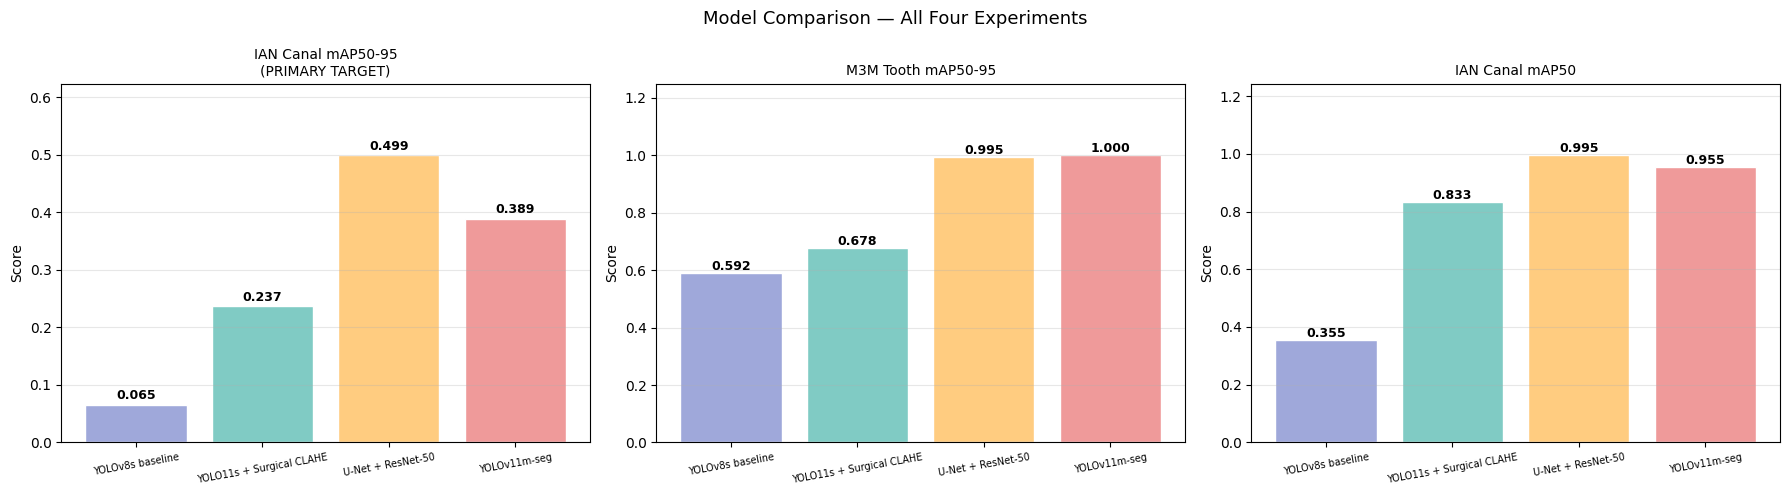

✓ Saved: /content/drive/MyDrive/FINAL_YEAR/DPT_1234new/MODELS/YOLO11m_seg/model_comparison.png


In [ ]:
comparison = pd.DataFrame([
    {
        'Model':        'YOLOv8s baseline',
        'IAN mAP50':    0.3549,
        'IAN mAP50-95': 0.0651,
        'M3M mAP50-95': 0.5918,
        'All mAP50-95': 0.3285,
    },
    {
        'Model':        'YOLO11s + Surgical CLAHE',
        'IAN mAP50':    0.8329,
        'IAN mAP50-95': 0.2366,
        'M3M mAP50-95': 0.6776,
        'All mAP50-95': 0.4571,
    },
    {
        'Model':        'U-Net + ResNet-50',
        'IAN mAP50':    0.9947,   # ← fill in from U-Net notebook output
        'IAN mAP50-95': 0.4993,   # ← fill in from U-Net notebook output
        'M3M mAP50-95': 0.9947,   # ← fill in from U-Net notebook output
        'All mAP50-95': 0.7470,   # ← fill in from U-Net notebook output
    },
    {
        'Model':        'YOLOv11m-seg (this run)',
        'IAN mAP50':    round(ian_test_metrics['mAP50'],    4),
        'IAN mAP50-95': round(ian_test_metrics['mAP50-95'], 4),
        'M3M mAP50-95': round(m3m_test_metrics['mAP50-95'], 4),
        'All mAP50-95': round((ian_test_metrics['mAP50-95'] + m3m_test_metrics['mAP50-95']) / 2, 4),
    },
])

print(comparison.to_string(index=False))
comparison.to_csv(os.path.join(MODEL_SAVE_DIR, 'model_comparison.csv'), index=False)

# Visual bar chart
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle('Model Comparison — All Four Experiments', fontsize=13)
colors  = ['#9FA8DA', '#80CBC4', '#FFCC80', '#EF9A9A']
models  = [m.split(' (')[0][:24] for m in comparison['Model'].tolist()]

for ax, col, title in [
    (axes[0], 'IAN mAP50-95', 'IAN Canal mAP50-95\n(PRIMARY TARGET)'),
    (axes[1], 'M3M mAP50-95', 'M3M Tooth mAP50-95'),
    (axes[2], 'IAN mAP50',    'IAN Canal mAP50'),
]:
    vals = comparison[col].tolist()
    bars = ax.bar(models, vals, color=colors, edgecolor='white')
    ax.set_title(title, fontsize=10)
    ax.set_ylim(0, max(vals) * 1.25)
    ax.set_ylabel('Score')
    ax.tick_params(axis='x', labelsize=7, rotation=10)
    ax.grid(axis='y', alpha=0.3)
    for bar, v in zip(bars, vals):
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.01,
                f'{v:.3f}', ha='center', fontsize=9, fontweight='bold')

plt.tight_layout()
cmp_path = os.path.join(MODEL_SAVE_DIR, 'model_comparison.png')
plt.savefig(cmp_path, dpi=150, bbox_inches='tight')
plt.show()
print(f'✓ Saved: {cmp_path}')

## 13. Qualitative Results — Predicted Masks on Test Images

For each test image: preprocessed input, GT IAN mask, predicted IAN mask, GT M3M, predicted M3M.  
Layout mirrors the U-Net qualitative section.

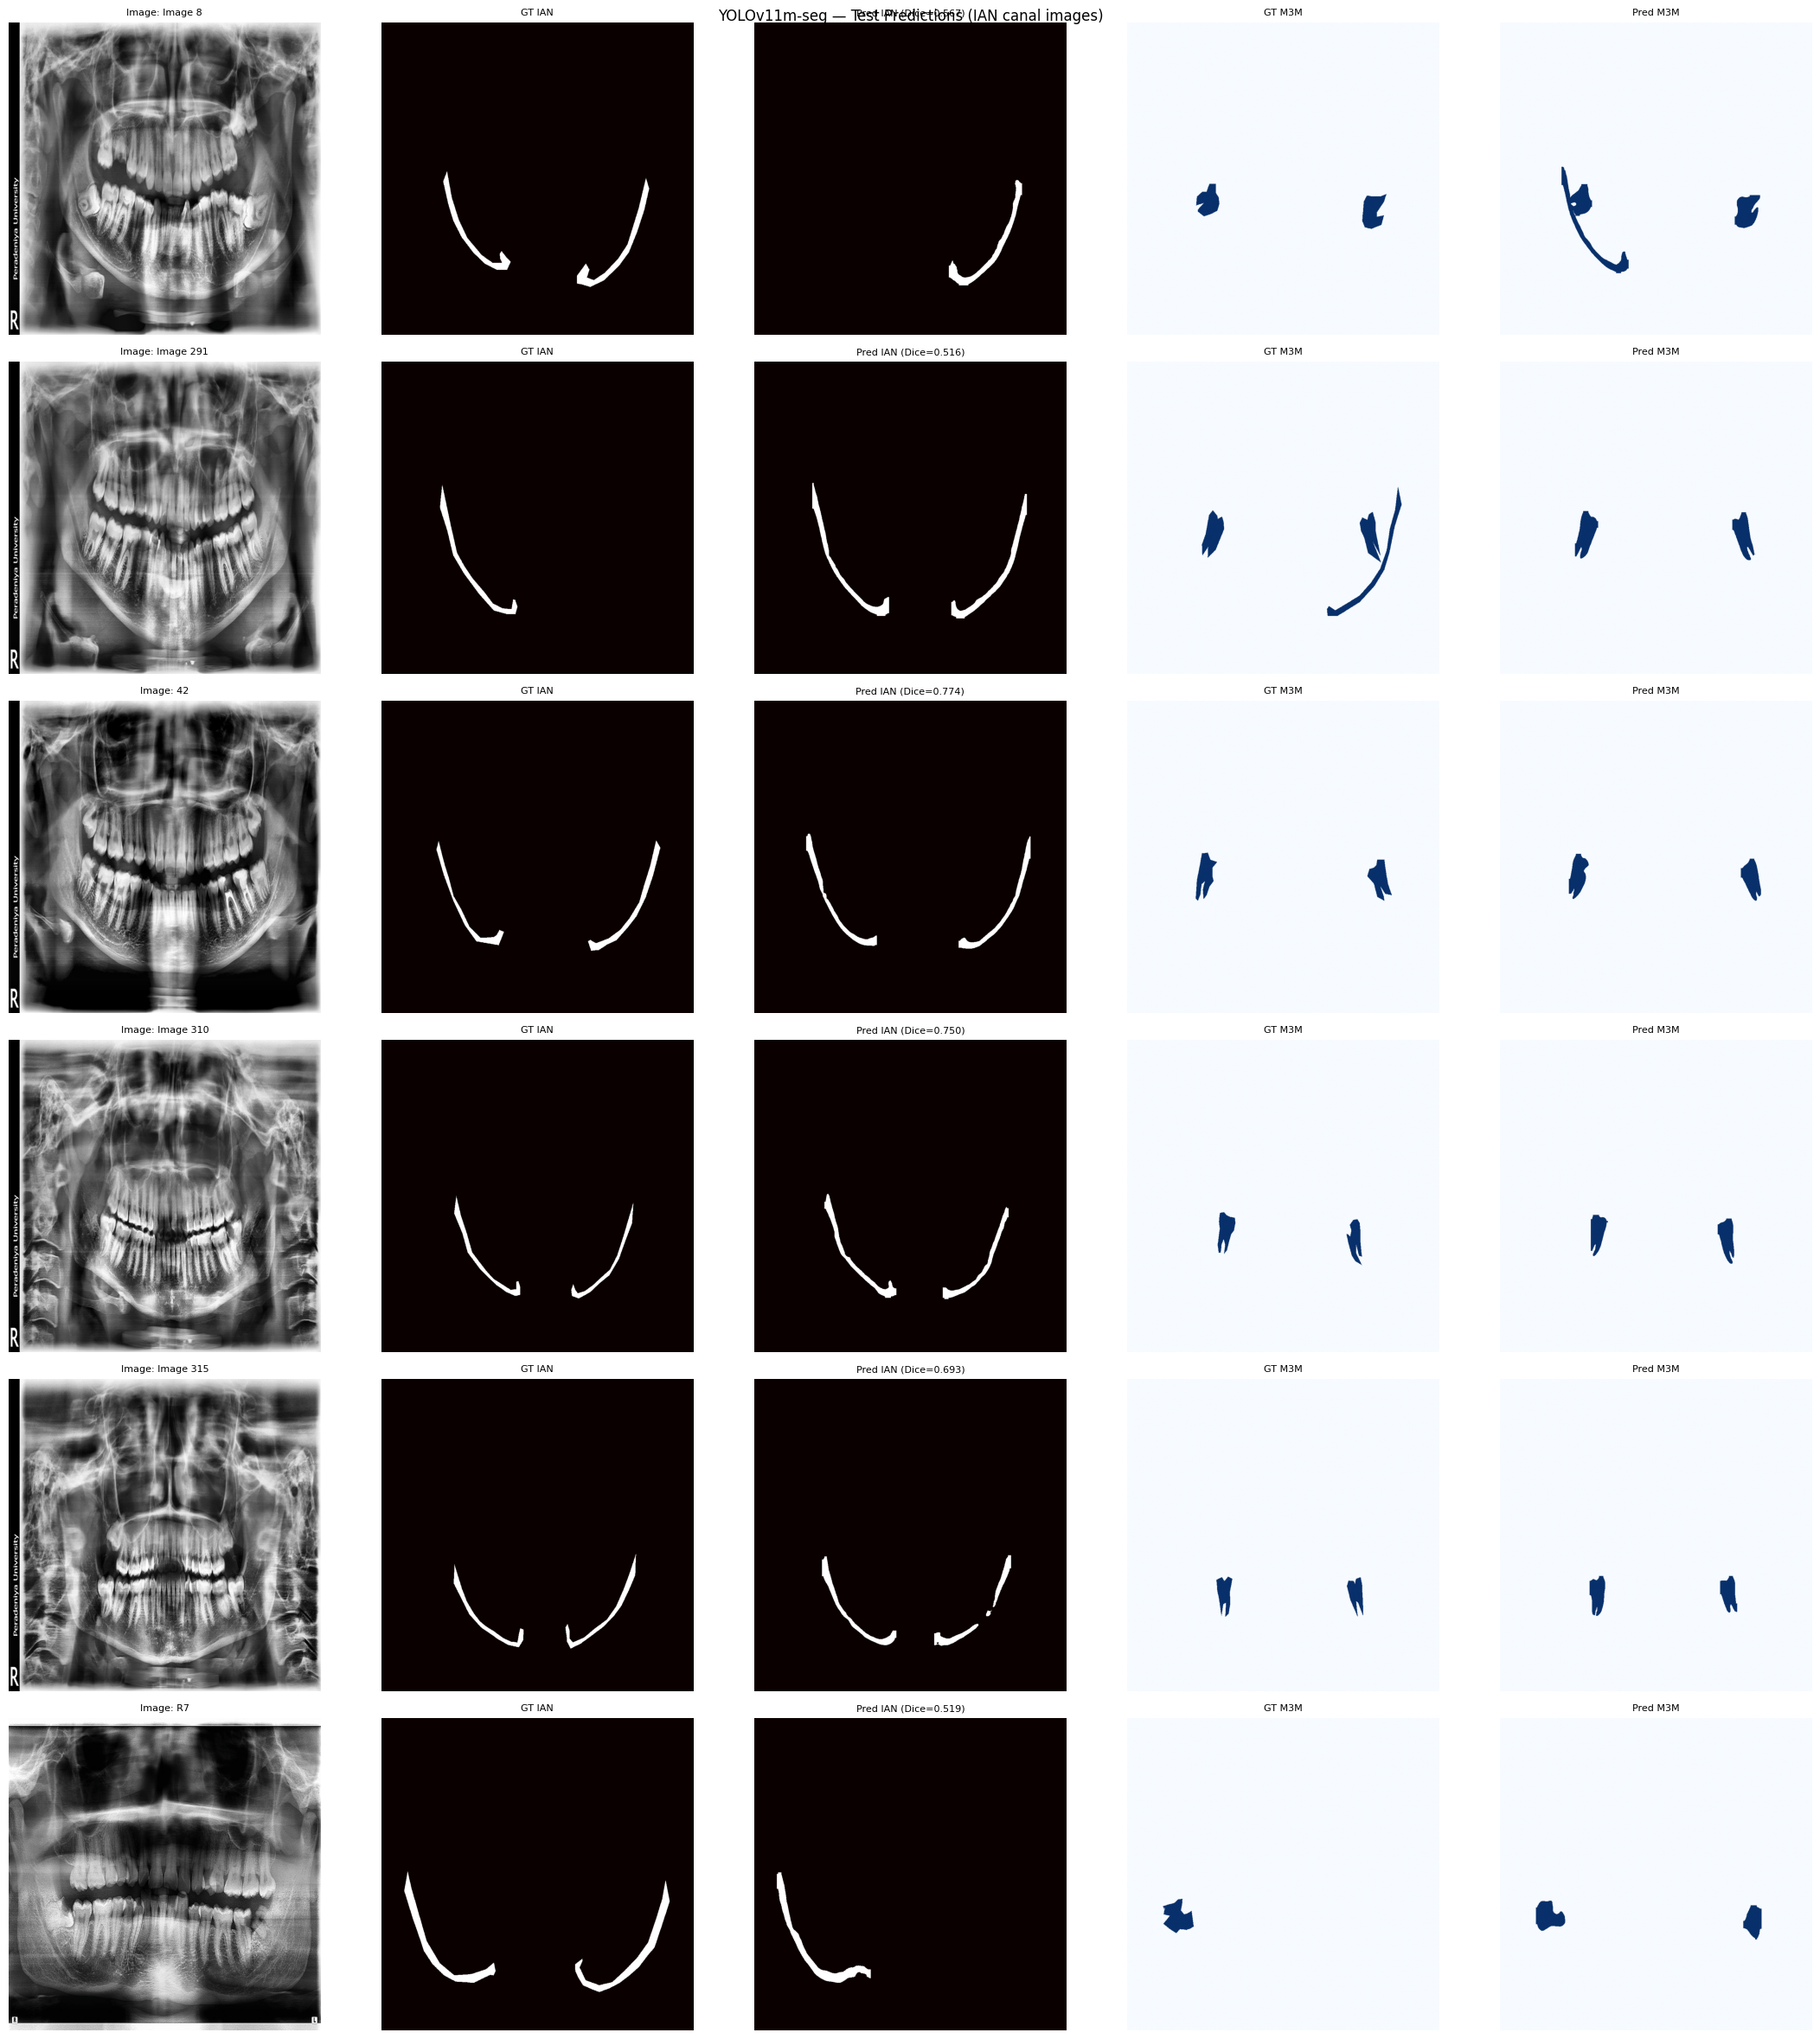

✓ Qualitative results saved


In [ ]:
def visualise_predictions_yolo(best_model, test_img_infos, img_to_anns,
                                 ian_cat_id, m3m_cat_id, img_dir, img_size, n=6,
                                 save_path=None):
    """Show GT vs predicted masks for n IAN-positive test images."""
    # Pick IAN-positive images
    ian_infos = [
        info for info in test_img_infos
        if any(a['category_id'] == ian_cat_id for a in img_to_anns.get(info['id'], []))
    ][:n]

    n_show = len(ian_infos)
    fig, axes = plt.subplots(n_show, 5, figsize=(22, 4 * n_show))
    if n_show == 1:
        axes = axes[np.newaxis]

    cols = ['Original (preprocessed)', 'GT: IAN mask', 'Pred: IAN mask',
            'GT: M3M mask', 'Pred: M3M mask']
    for ax, col in zip(axes[0], cols):
        ax.set_title(col, fontsize=9, fontweight='bold')
    fig.suptitle('YOLOv11m-seg — Test Predictions (IAN canal images)', fontsize=12)

    for row, info in enumerate(ian_infos):
        stem     = Path(info['file_name']).stem
        img_path = os.path.join(img_dir, 'images', 'test', f'{stem}.jpg')
        img_bgr  = cv2.imread(img_path)
        img_rgb  = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

        anns    = img_to_anns.get(info['id'], [])
        h, w    = info['height'], info['width']
        ian_gt  = coco_polygons_to_mask(anns, ian_cat_id, h, w, img_size)
        m3m_gt  = coco_polygons_to_mask(anns, m3m_cat_id, h, w, img_size)

        res      = best_model.predict(img_path, imgsz=img_size, conf=0.25, verbose=False)[0]
        ian_pred = yolo_masks_to_binary(res, CLASS_IAN, img_size)
        m3m_pred = yolo_masks_to_binary(res, CLASS_M3M, img_size)

        ian_d = dice_score_np(ian_pred, ian_gt)

        for ax, data, cmap, title in [
            (axes[row, 0], img_rgb,    None,    f'Image: {stem[:20]}'),
            (axes[row, 1], ian_gt,     'hot',   'GT IAN'),
            (axes[row, 2], ian_pred,   'hot',   f'Pred IAN (Dice={ian_d:.3f})'),
            (axes[row, 3], m3m_gt,     'Blues', 'GT M3M'),
            (axes[row, 4], m3m_pred,   'Blues', 'Pred M3M'),
        ]:
            if cmap:
                ax.imshow(data, cmap=cmap, vmin=0, vmax=1)
            else:
                ax.imshow(data)
            ax.set_title(title, fontsize=8)
            ax.axis('off')

    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=120, bbox_inches='tight')
    plt.show()


visualise_predictions_yolo(
    best_model, SPLITS['test'], img_to_anns,
    IAN_CAT_ID, M3M_CAT_ID, WORK_DIR, IMG_SIZE, n=6,
    save_path=os.path.join(MODEL_SAVE_DIR, 'test_predictions.png')
)
print('✓ Qualitative results saved')

## 14. IAN Canal Dice Distribution Across Test Set

Shows per-image Dice scores — important for clinical reliability.  
Mirrors Section 18 of the U-Net notebook.

Per-image IAN analysis:   0%|          | 0/73 [00:00<?, ?it/s]

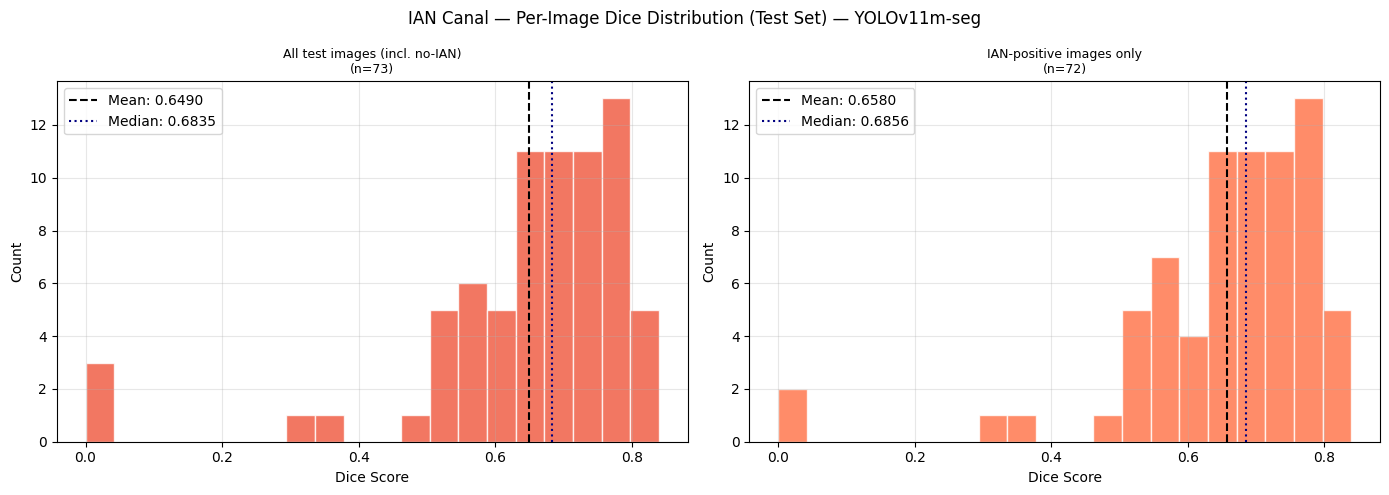

IAN Dice (all test)     : mean=0.6490  std=0.1676
IAN Dice (IAN-only)     : mean=0.6580  std=0.1501
IAN IoU  (all test)     : mean=0.4987
% test images Dice>0.5  : 93.1%
% test images Dice>0.7  : 44.4%


In [ ]:
per_image_dice = []
per_image_iou  = []
ian_only_dice  = []

for info in tqdm(SPLITS['test'], desc='Per-image IAN analysis'):
    stem     = Path(info['file_name']).stem
    img_path = os.path.join(WORK_DIR, 'images', 'test', f'{stem}.jpg')
    if not os.path.exists(img_path):
        continue

    anns   = img_to_anns.get(info['id'], [])
    h, w   = info['height'], info['width']
    ian_gt = coco_polygons_to_mask(anns, IAN_CAT_ID, h, w, IMG_SIZE)

    res      = best_model.predict(img_path, imgsz=IMG_SIZE, conf=0.25, verbose=False)[0]
    ian_pred = yolo_masks_to_binary(res, CLASS_IAN, IMG_SIZE)

    d = dice_score_np(ian_pred, ian_gt)
    j = iou_score_np(ian_pred, ian_gt)
    per_image_dice.append(d)
    per_image_iou.append(j)

    has_ian = any(a['category_id'] == IAN_CAT_ID for a in img_to_anns.get(info['id'], []))
    if has_ian:
        ian_only_dice.append(d)


fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('IAN Canal — Per-Image Dice Distribution (Test Set) — YOLOv11m-seg', fontsize=12)

for ax, data, title, color in [
    (axes[0], per_image_dice, 'All test images (incl. no-IAN)',   '#EF553B'),
    (axes[1], ian_only_dice,  'IAN-positive images only',          '#FF7043'),
]:
    ax.hist(data, bins=20, color=color, alpha=0.8, edgecolor='white')
    ax.axvline(np.mean(data), color='black', linestyle='--', label=f'Mean: {np.mean(data):.4f}')
    ax.axvline(np.median(data), color='navy', linestyle=':', label=f'Median: {np.median(data):.4f}')
    ax.set_xlabel('Dice Score'); ax.set_ylabel('Count')
    ax.set_title(f'{title}\n(n={len(data)})', fontsize=9)
    ax.legend(); ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(MODEL_SAVE_DIR, 'ian_dice_distribution.png'), dpi=150, bbox_inches='tight')
plt.show()

print(f'IAN Dice (all test)     : mean={np.mean(per_image_dice):.4f}  std={np.std(per_image_dice):.4f}')
print(f'IAN Dice (IAN-only)     : mean={np.mean(ian_only_dice):.4f}  std={np.std(ian_only_dice):.4f}')
print(f'IAN IoU  (all test)     : mean={np.mean(per_image_iou):.4f}')
print(f'% test images Dice>0.5  : {sum(d > 0.5 for d in ian_only_dice) / len(ian_only_dice) * 100:.1f}%')
print(f'% test images Dice>0.7  : {sum(d > 0.7 for d in ian_only_dice) / len(ian_only_dice) * 100:.1f}%')

## 15. Clinical Proximity Analysis — IAN to M3M Distance

Computes minimum pixel distance between predicted IAN canal mask and M3M mask.  
Mirrors Section 19 of the U-Net notebook.

Proximity analysis:   0%|          | 0/30 [00:00<?, ?it/s]

       pred_min_dist  gt_min_dist
count          29.00        29.00
mean            5.04         6.99
std             5.09         8.47
min             0.00         0.00
25%             2.00         1.40
50%             3.00         4.00
75%             6.40         8.60
max            20.50        33.20


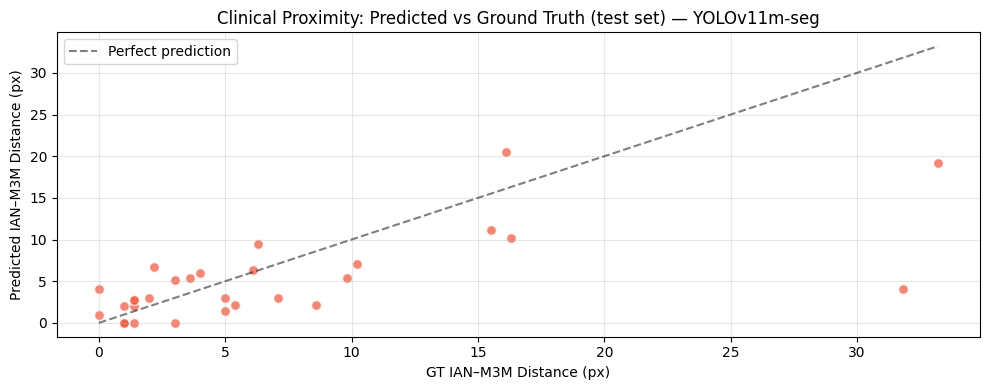


Pred vs GT proximity correlation: r = 0.6677


In [ ]:
proximity_records = []

for info in tqdm(SPLITS['test'][:30], desc='Proximity analysis'):
    stem     = Path(info['file_name']).stem
    img_path = os.path.join(WORK_DIR, 'images', 'test', f'{stem}.jpg')
    if not os.path.exists(img_path):
        continue

    anns   = img_to_anns.get(info['id'], [])
    h, w   = info['height'], info['width']
    ian_gt = coco_polygons_to_mask(anns, IAN_CAT_ID, h, w, IMG_SIZE)
    m3m_gt = coco_polygons_to_mask(anns, M3M_CAT_ID, h, w, IMG_SIZE)

    res      = best_model.predict(img_path, imgsz=IMG_SIZE, conf=0.25, verbose=False)[0]
    ian_pred = yolo_masks_to_binary(res, CLASS_IAN, IMG_SIZE)
    m3m_pred = yolo_masks_to_binary(res, CLASS_M3M, IMG_SIZE)

    ian_pts  = np.column_stack(np.where(ian_pred > 0.5))
    m3m_pts  = np.column_stack(np.where(m3m_pred > 0.5))

    if len(ian_pts) > 5 and len(m3m_pts) > 5:
        ian_s = ian_pts[np.random.choice(len(ian_pts), min(500, len(ian_pts)), replace=False)]
        m3m_s = m3m_pts[np.random.choice(len(m3m_pts), min(500, len(m3m_pts)), replace=False)]
        dist  = cdist(ian_s.astype(float), m3m_s.astype(float)).min()

        ian_gt_pts = np.column_stack(np.where(ian_gt > 0))
        m3m_gt_pts = np.column_stack(np.where(m3m_gt > 0))
        gt_dist = None
        if len(ian_gt_pts) > 0 and len(m3m_gt_pts) > 0:
            gt_s1   = ian_gt_pts[np.random.choice(len(ian_gt_pts), min(200, len(ian_gt_pts)), replace=False)]
            gt_s2   = m3m_gt_pts[np.random.choice(len(m3m_gt_pts), min(200, len(m3m_gt_pts)), replace=False)]
            gt_dist = cdist(gt_s1.astype(float), gt_s2.astype(float)).min()

        proximity_records.append({
            'image':         info['file_name'],
            'pred_min_dist': round(dist, 1),
            'gt_min_dist':   round(gt_dist, 1) if gt_dist is not None else None,
        })


if proximity_records:
    df_prox = pd.DataFrame(proximity_records).dropna()
    print(df_prox[['pred_min_dist', 'gt_min_dist']].describe().round(2))

    fig, ax = plt.subplots(figsize=(10, 4))
    ax.scatter(df_prox['gt_min_dist'], df_prox['pred_min_dist'],
               alpha=0.7, color='#EF553B', edgecolors='white', s=50)
    lim = max(df_prox[['gt_min_dist', 'pred_min_dist']].max())
    ax.plot([0, lim], [0, lim], 'k--', alpha=0.5, label='Perfect prediction')
    ax.set_xlabel('GT IAN–M3M Distance (px)')
    ax.set_ylabel('Predicted IAN–M3M Distance (px)')
    ax.set_title('Clinical Proximity: Predicted vs Ground Truth (test set) — YOLOv11m-seg')
    ax.legend(); ax.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(os.path.join(MODEL_SAVE_DIR, 'proximity_scatter.png'), dpi=150, bbox_inches='tight')
    plt.show()

    corr = df_prox[['gt_min_dist', 'pred_min_dist']].corr().iloc[0, 1]
    print(f'\nPred vs GT proximity correlation: r = {corr:.4f}')
    df_prox.to_csv(os.path.join(MODEL_SAVE_DIR, 'proximity_results.csv'), index=False)
else:
    print('No test images had both IAN and M3M detected at conf=0.25')

## 16. Save All Outputs

In [ ]:
# Save full metrics JSON
all_metrics = {
    'IAN': {k: round(v, 4) for k, v in ian_test_metrics.items()},
    'M3M': {k: round(v, 4) for k, v in m3m_test_metrics.items()},
}
with open(os.path.join(MODEL_SAVE_DIR, 'test_metrics.json'), 'w') as f:
    json.dump(all_metrics, f, indent=2)

print(f'All outputs in: {MODEL_SAVE_DIR}')
print('\nFiles saved:')
for root, dirs, files in os.walk(MODEL_SAVE_DIR):
    level = root.replace(MODEL_SAVE_DIR, '').count(os.sep)
    indent = '  ' * level
    if level < 3:
        for fn in sorted(files):
            sz = os.path.getsize(os.path.join(root, fn)) / 1e6
            print(f'  {indent}{fn}  ({sz:.1f} MB)')

print(f'\n🏆 Best model weights: {BEST_PT}')

All outputs in: /content/drive/MyDrive/FINAL_YEAR/DPT_1234new/MODELS/YOLO11m_seg

Files saved:
  dataset_sanity.png  (0.7 MB)
  ian_dice_distribution.png  (0.1 MB)
  model_comparison.csv  (0.0 MB)
  model_comparison.png  (0.1 MB)
  proximity_results.csv  (0.0 MB)
  proximity_scatter.png  (0.1 MB)
  test_metrics.json  (0.0 MB)
  test_predictions.png  (2.2 MB)
  training_curves.png  (0.2 MB)
    data.yaml  (0.0 MB)
      train.cache  (0.4 MB)
      val.cache  (0.1 MB)
    BoxF1_curve.png  (0.1 MB)
    BoxPR_curve.png  (0.1 MB)
    BoxP_curve.png  (0.1 MB)
    BoxR_curve.png  (0.1 MB)
    MaskF1_curve.png  (0.1 MB)
    MaskPR_curve.png  (0.1 MB)
    MaskP_curve.png  (0.1 MB)
    MaskR_curve.png  (0.1 MB)
    args.yaml  (0.0 MB)
    confusion_matrix.png  (0.1 MB)
    confusion_matrix_normalized.png  (0.1 MB)
    labels.jpg  (0.1 MB)
    results.csv  (0.0 MB)
    results.png  (0.5 MB)
    train_batch0.jpg  (0.3 MB)
    train_batch1.jpg  (0.3 MB)
    train_batch2.jpg  (0.3 MB)
    val_batch0